# Publications over the years: plots

Plots of the publications of the research centres and universities of Catalonia (Portal de la Recerca de Catalunya, through Dades Obertes Catalunya).

Requirements: run `05a_alba_domains_topics_processing.ipynb` first. This notebook reads `data/processed` and `data/external/papers_cleaned.gencat.parquet`. The figures are saved in `plots/alba`; the `savefig` lines that are commented are not saved (uncomment them to save the figure).

Contents:
1. Total publications
2. Publications by domain
3. Growth: log-log regression
4. COVID-19
5. Normalized evolution by domain
6. Contribution of each domain to the total
7. Domains and topics

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Base paths for data
DATA = Path("../data")
EXTERNAL = DATA / "external"
PROCESSED = DATA / "processed"

# Folder to save the plots
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)

# CVD-safe palette: the same color for each domain in all the plots
colors = {'Life Sciences': '#009E73',      # turquoise
          'Physical Sciences': '#0072B2',  # blue
          'Social Sciences': '#E69F00',    # yellow
          'Health Sciences': '#CC79A7'}    # purple

# Order of the domains (stacks and legends)
order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]

## 1. Total publications

### PLOT 1: all publications over the years

First look at the data: unique publications (one per DOI) per year. We see an explosion of publications from ~1990 that we want to characterize.

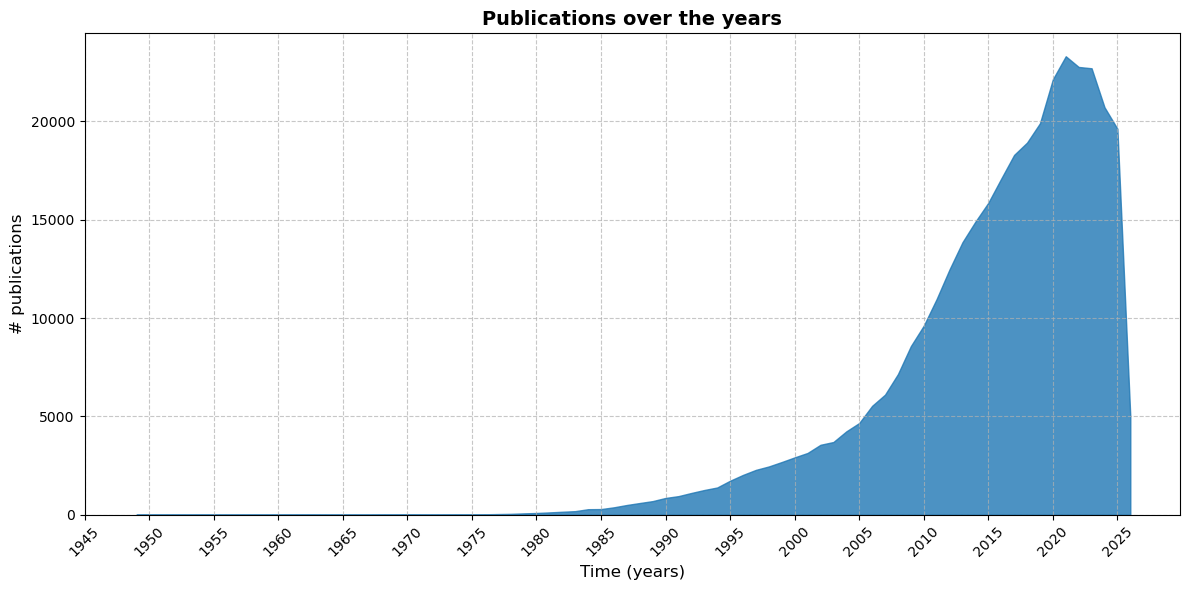

In [2]:
df = pd.read_parquet(EXTERNAL / "papers_cleaned.gencat.parquet")
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year.astype(int) # from the date, we only want the year

# FILTER DUPLICATED DOIS-----------------------------------------------
df_unics = df.drop_duplicates(subset=["doi"])
#----------------------------------------------------------------------

# Count publications per year
publicacions_per_any = df_unics['year'].value_counts().sort_index()

anys = publicacions_per_any.index
quantitat = publicacions_per_any.values

# PLOT
plt.figure(figsize=(12, 6))
plt.stackplot(anys, quantitat, labels=['Total publications'], color='#1f77b4', alpha=0.8)
plt.title("Publications over the years", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("# publications", fontsize=12)
ticks_anys = np.arange(1945, max(anys) + 1, 5)
plt.xticks(ticks_anys, rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

#plt.savefig(f"{output_dir}/total_publications_over_the_years.png", dpi=300, bbox_inches='tight')
plt.show()

## 2. Publications by domain

### PLOT 2: area chart by domain

Publications per year stacked by domain (only papers with a domain assigned). Around 1990 the first online publications appear (through online journals), and the growth takes off. We want to see which domains drive it. In order to characterize this growth, the inset shows the same stacked curves in log-log scale, and the dashed line marks the start of COVID-19 (2020).

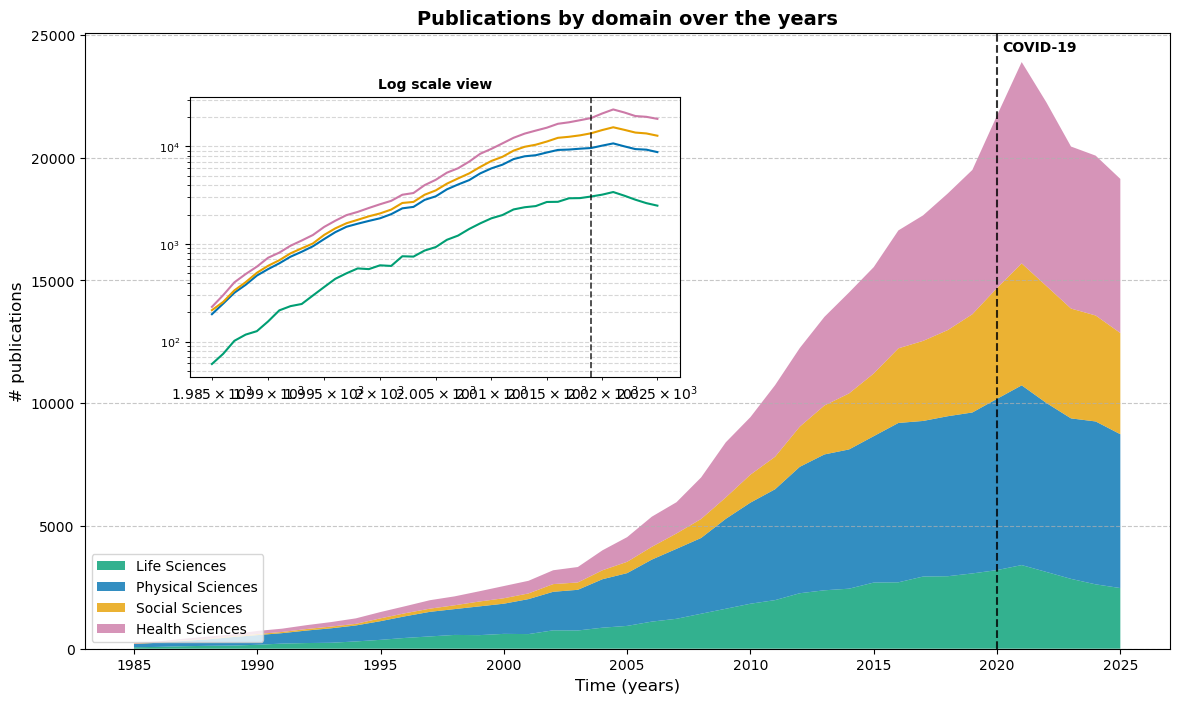

In [5]:
df = pd.read_parquet("../data/processed/all_publications_enriched_new.parquet")

# Only papers with domain assigned
df_plots = df.dropna(subset=["domain_name"])

# Table for the plot: rows = years, columns = domains, values = number of papers
taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
taula_dominis = taula_dominis[order] # apply the order to the columns

# Filter the years: 1985-2025
taula_dominis = taula_dominis[(taula_dominis.index >= 1985) & (taula_dominis.index <= 2025)]

anys = taula_dominis.index
quantitats = [taula_dominis[col].values for col in taula_dominis.columns]
etiquetes = taula_dominis.columns.tolist()
colors_list = [colors[col] for col in etiquetes]

cumsum = taula_dominis.cumsum(axis=1) # stacked values, used in the inset

# PLOT
fig = plt.figure(figsize=(14, 8))
ax_main = fig.add_subplot(111)
ax_main.stackplot(anys, quantitats, labels=etiquetes, colors=colors_list, alpha=0.8)
ax_main.set_title("Publications by domain over the years", fontsize=14, fontweight='bold')
ax_main.set_xlabel("Time (years)", fontsize=12)
ax_main.set_ylabel("# publications", fontsize=12)
ax_main.grid(axis='y', linestyle='--', alpha=0.7)
ax_main.legend(loc='lower left')

# Line to indicate COVID-19
ax_main.axvline(x=2020, color='black', linestyle='--', linewidth=1.5, alpha=0.8)
ax_main.text(2020.2, ax_main.get_ylim()[1]*0.97, 'COVID-19', color='black', fontsize=10, fontweight='bold')

# Inset: log-log view
ax_inset = fig.add_axes([0.2, 0.45, 0.35, 0.35])
for i, col in enumerate(cumsum.columns):
    ax_inset.plot(anys, cumsum[col], color=colors_list[i], linewidth=1.5)
ax_inset.set_yscale('log')
ax_inset.set_xscale('log')
ax_inset.set_title("Log scale view", fontsize=10, fontweight='bold')
ax_inset.grid(axis="y", linestyle='--', alpha=0.5, which='both')
ax_inset.tick_params(axis='both', labelsize=8)
ax_inset.axvline(x=2019, color='black', linestyle='--', linewidth=1.2, alpha=0.8)

#plt.savefig(f"{output_dir}/area_chart_publications_by_domain.png", dpi=300, bbox_inches='tight')
plt.show()

## 3. Growth: log-log regression

In a semi-log plot a straight line means exponential growth, and in a log-log plot it means a power law, $y = 10^b \cdot x^\alpha$. We fit $\log y = \alpha \log x + b$ to the years before COVID-19 (1990-2019) to characterize the growth with the exponent $\alpha$. The years span a short range, so the fit behaves almost like an exponential.

### PLOT 3: total publications and log-log regression

Left: area chart by domain with the total (black line). Right: the total in log-log scale. The filled points are the ones used for the regression (1990-2019) and the red line is the fit, with its equation and $R^2$. We do it first with the total to quantify the growth we see in the area chart.

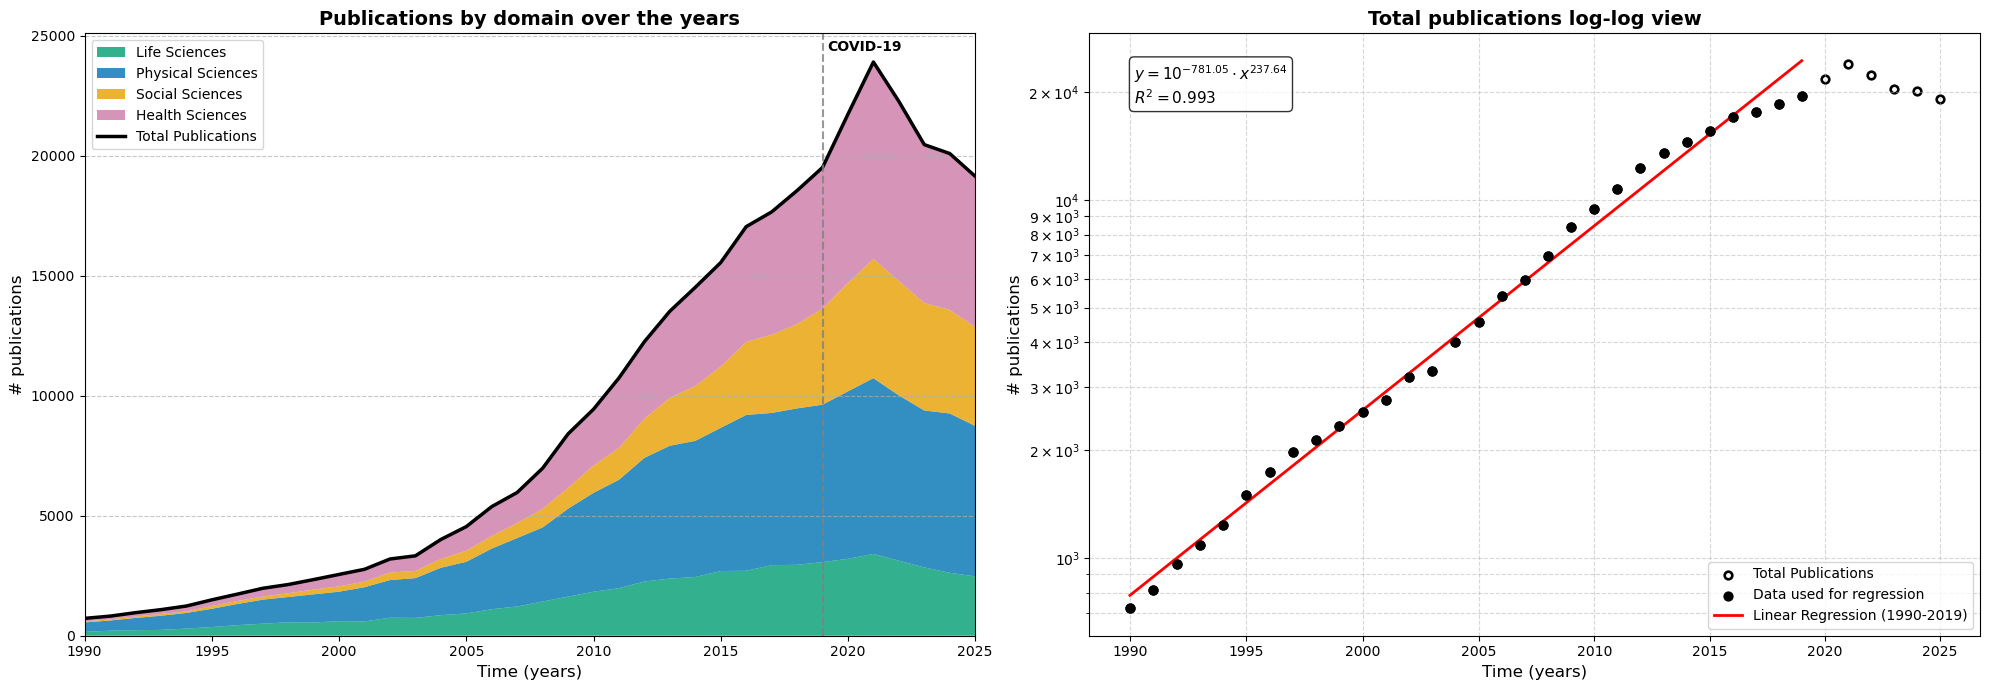

In [6]:
df = pd.read_parquet("../data/processed/all_publications_enriched_new.parquet")
df_plots = df.dropna(subset=["domain_name"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
taula_dominis = taula_dominis[order]
taula_dominis = taula_dominis[(taula_dominis.index >= 1990) & (taula_dominis.index <= 2025)]

anys = taula_dominis.index
quantitats = [taula_dominis[col].values for col in taula_dominis.columns]
etiquetes = taula_dominis.columns.tolist()
colors_list = [colors[col] for col in etiquetes]

# Total publications per year
total_per_any = taula_dominis.sum(axis=1)
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(20, 7))

# PLOT LEFT-------------------------------------------------------------------------
ax_left.stackplot(anys, quantitats, labels=etiquetes, colors=colors_list, alpha=0.8)
ax_left.plot(anys, total_per_any, color='#000000', linewidth=2.5, label='Total Publications')
ax_left.set_title("Publications by domain over the years", fontsize=14, fontweight='bold')
ax_left.set_xlabel("Time (years)", fontsize=12)
ax_left.set_ylabel("# publications", fontsize=12)
ax_left.grid(axis='y', linestyle='--', alpha=0.7)
ax_left.set_xlim(anys.min(), anys.max())
ax_left.legend(loc='upper left')
ax_left.axvline(x=2019, color='gray', linestyle='--', linewidth=1.5, alpha=0.8)
ax_left.text(2019.2, ax_left.get_ylim()[1]*0.97, 'COVID-19', color='black', fontsize=10, fontweight='bold')

# PLOT RIGHT------------------------------------------------------------------------
ax_right.scatter(anys, total_per_any, color='white', edgecolor='#000000', linewidth=1.9, s=30, label='Total Publications')

# LINEAR REGRESSION from 1990 to 2019
mask = (anys >= 1990) & (anys <= 2019)
anys_reg = anys[mask]
total_reg = total_per_any[mask]

# Points used in the regression
ax_right.scatter(anys[mask], total_per_any[mask], color='#000000', edgecolor='#000000', linewidths=1.9, s=30, zorder=3, label='Data used for regression')

log_anys = np.log10(anys_reg) # Linear regression: log(y) = m * log(x) + b, so we adapt that
log_total = np.log10(total_reg)

# Fit (m and b calculus)
m, b = np.polyfit(log_anys, log_total, 1)

# R^2 calculus
total_pred = m * log_anys + b
ss_res = np.sum((log_total - total_pred) ** 2)
ss_tot = np.sum((log_total - np.mean(log_total)) ** 2)
r_squared = 1 - (ss_res / ss_tot)

# Linear regression
x_fit = np.linspace(min(log_anys), max(log_anys), 100)
y_fit = m * x_fit + b
ax_right.plot(10**x_fit, 10**y_fit, color='red', linewidth=2, label='Linear Regression (1990-2019)')
text_eq = f"$y = 10^{{{b:.2f}}} \\cdot x^{{{m:.2f}}}$\n$R^2 = {r_squared:.3f}$"
ax_right.text(0.05, 0.95, text_eq, transform=ax_right.transAxes, fontsize=11,
              verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax_right.set_xscale('log')
ax_right.set_yscale('log')
ax_right.set_title("Total publications log-log view", fontsize=14, fontweight='bold')
ax_right.set_xlabel("Time (years)", fontsize=12)
ax_right.set_ylabel("# publications", fontsize=12)

anys_x = [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025]
ax_right.set_xticks(anys_x)
ax_right.set_xticklabels(anys_x)
valors_y = [1e3, 2e3, 3e3, 4e3, 5e3, 6e3, 7e3, 8e3, 9e3, 1e4, 2e4]
etiquetes_y = [r'$10^3$',
    r'$2 \times 10^3$',
    r'$3 \times 10^3$',
    r'$4 \times 10^3$',
    r'$5 \times 10^3$',
    r'$6 \times 10^3$',
    r'$7 \times 10^3$',
    r'$8 \times 10^3$',
    r'$9 \times 10^3$',
    r'$10^4$',
    r'$2 \times 10^4$']
ax_right.set_yticks(valors_y)
ax_right.set_yticklabels(etiquetes_y)

ax_right.grid(True, linestyle='--', alpha=0.5, which='both')
ax_right.legend(loc='lower right')
plt.tight_layout()

plt.savefig(f"{output_dir}/publications_comparison_with_regression.png", dpi=300, bbox_inches='tight')
plt.show()

### PLOT 4a: log-log regression by domain

Same regression for each domain, to see if all of them grow at the same pace. The legend gives the exponent $\alpha$ and $R^2$ of each domain the data from 1990-2025, which is the same as the previous plot. The printed summary compares the exponent of the total with the mean of the exponents of the domains (the total weights each domain by its size, so it is not the plain mean).

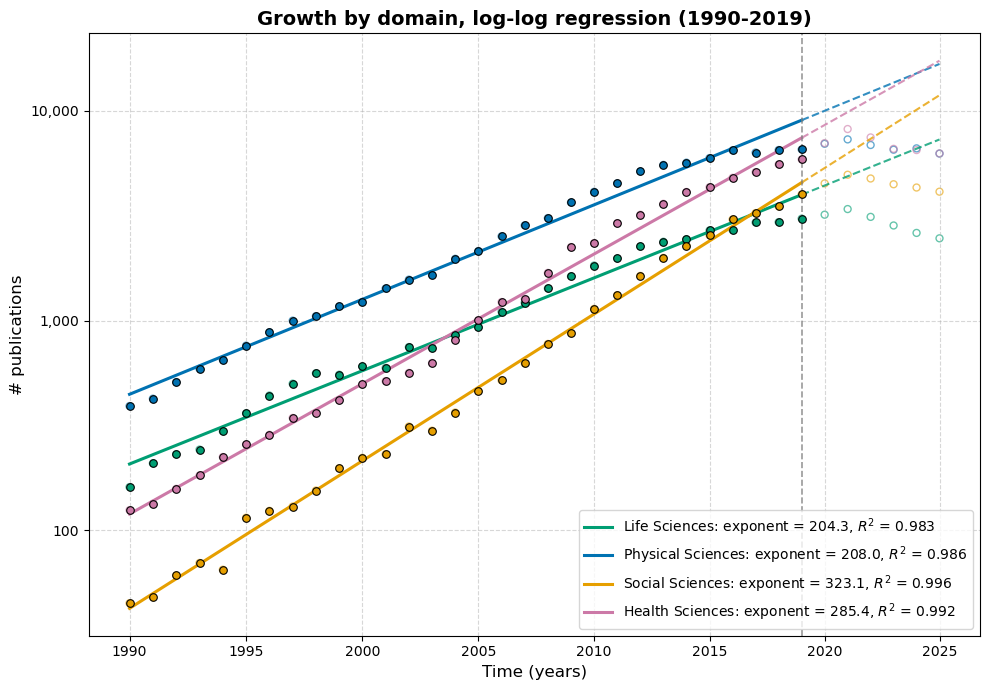

                   exponent      R2
domain                             
Life Sciences      204.3488  0.9826
Physical Sciences  208.0010  0.9856
Social Sciences    323.0962  0.9957
Health Sciences    285.4375  0.9923

Total (sum of domains):      exponent = 237.6417
Unweighted mean of domains:  exponent = 255.2209
Share-weighted mean:         exponent = 244.1637


In [7]:
# LOG-LOG REGRESSION BY DOMAIN (1990-2019)
fit_df = taula_dominis[(taula_dominis.index >= 1990) & (taula_dominis.index <= 2019)]

fig, ax = plt.subplots(figsize=(10, 7))
resultats = []

for domain in taula_dominis.columns:
    col = colors[domain]

    # All the points (hollow = not used in the regression)
    ax.scatter(taula_dominis.index.values, taula_dominis[domain].values, s=25, facecolors="none", edgecolors=col, alpha=0.6)

    # Fit: log(y) = m * log(x) + b
    log_x = np.log10(fit_df.index.values.astype(float))
    log_y = np.log10(fit_df[domain].values.astype(float))
    m, b = np.polyfit(log_x, log_y, 1)
    r2 = 1 - np.sum((log_y - (m * log_x + b)) ** 2) / np.sum((log_y - log_y.mean()) ** 2)
    resultats.append([domain, m, r2])

    # Points used in the regression (filled)
    ax.scatter(fit_df.index, fit_df[domain], s=30, color=col, edgecolor="black", linewidths=0.8, zorder=3)

    # Fitted line (solid) and extrapolation (dashed)
    y_fit = np.arange(1990, 2020)
    y_ext = np.arange(2019, 2026)
    ax.plot(y_fit, 10 ** (m * np.log10(y_fit) + b), color=col, lw=2.2, label=f"{domain}: exponent = {m:.1f}, $R^2$ = {r2:.3f}")
    ax.plot(y_ext, 10 ** (m * np.log10(y_ext) + b), color=col, lw=1.5, ls="--", alpha=0.8)

ax.axvline(2019, color="gray", ls="--", lw=1.2, alpha=0.8)
ax.set_yscale("log")
ax.set_xscale("log")
ax.set_xticks([1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025])
ax.set_xticklabels([1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025])
ax.minorticks_off()
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_xlabel("Time (years)", fontsize=12)
ax.set_ylabel("# publications", fontsize=12)
ax.set_title("Growth by domain, log-log regression (1990-2019)", fontsize=14, fontweight="bold")
ax.grid(True, ls="--", alpha=0.5, which="both")
ax.legend(loc="lower right", fontsize=10)
plt.tight_layout()

plt.savefig(f"{output_dir}/publications_regression_by_domain.png", dpi=300, bbox_inches="tight")
plt.show()

# Exponent of the total vs. mean of the exponents of the domains
resultats = pd.DataFrame(resultats, columns=["domain", "exponent", "R2"]).set_index("domain")
m_tot, _ = np.polyfit(log_x, np.log10(fit_df.sum(axis=1).values.astype(float)), 1)
shares = fit_df.sum() / fit_df.sum().sum()
print(resultats.round(4))
print(f"\nTotal (sum of domains):      exponent = {m_tot:.4f}")
print(f"Unweighted mean of domains:  exponent = {resultats['exponent'].mean():.4f}")
print(f"Share-weighted mean:         exponent = {(resultats['exponent'] * shares).sum():.4f}")

### PLOT 4b: log-log regression by domain and total

Same as 4a with the total added (black), and the legend also gives the approximate relative growth per year, $\alpha$ / (mean year). It lets us compare the growth of the domains with the total in a single figure.

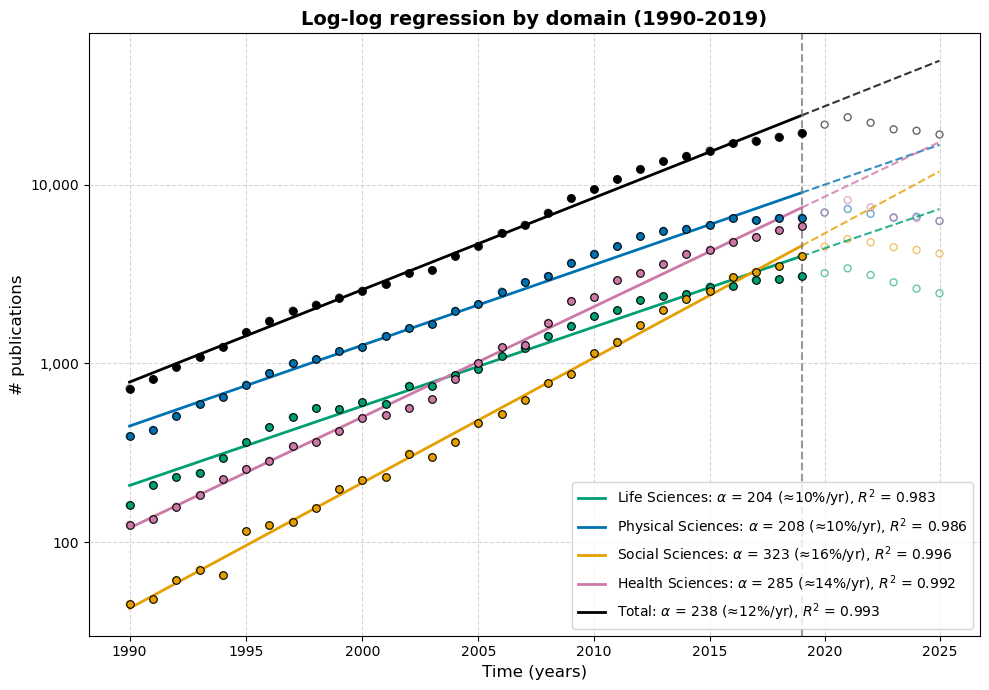

              domain    alpha  growth_%/yr     R2
0      Life Sciences  204.349       10.195  0.983
1  Physical Sciences  208.001       10.377  0.986
2    Social Sciences  323.096       16.119  0.996
3    Health Sciences  285.437       14.240  0.992
4              Total  237.642       11.855  0.993


In [8]:
# LOG-LOG REGRESSION + TOTAL (1990-2019)
anys = taula_dominis.index
mask = (anys >= 1990) & (anys <= 2019)
anys_reg = anys[mask]

taula_total = taula_dominis.copy()
taula_total["Total"] = taula_dominis.sum(axis=1)
colors_tot = {**colors, "Total": "#000000"}

fig, ax = plt.subplots(figsize=(10, 7))
resultats = []

for col in taula_total.columns:
    # Points: filled = used in the regression, hollow = not used (2020-2025)
    ax.scatter(anys, taula_total[col], s=25, facecolors="none", edgecolors=colors_tot[col], alpha=0.6)
    ax.scatter(anys_reg, taula_total.loc[mask, col], s=30, color=colors_tot[col], edgecolor="#000000", linewidths=0.8, zorder=3)

    # Fit: log(y) = alpha * log(x) + b
    log_x = np.log10(anys_reg)
    log_y = np.log10(taula_total.loc[mask, col])
    alpha, b = np.polyfit(log_x, log_y, 1)
    r2 = 1 - np.sum((log_y - (alpha * log_x + b)) ** 2) / np.sum((log_y - log_y.mean()) ** 2)
    creixement = alpha / np.mean(anys_reg) * 100  # approx. relative growth per year (%)
    resultats.append([col, alpha, creixement, r2])

    # Fitted line (solid) and extrapolation to 2025 (dashed)
    x_fit = np.linspace(1990, 2019, 100)
    x_ext = np.linspace(2019, 2025, 20)
    ax.plot(x_fit, 10 ** (alpha * np.log10(x_fit) + b), color=colors_tot[col], linewidth=2,
            label=f"{col}: $\\alpha$ = {alpha:.0f} (≈{creixement:.0f}%/yr), $R^2$ = {r2:.3f}")
    ax.plot(x_ext, 10 ** (alpha * np.log10(x_ext) + b), color=colors_tot[col], linewidth=1.5, linestyle="--", alpha=0.8)

ax.axvline(x=2019, color="gray", linestyle="--", linewidth=1.5, alpha=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025])
ax.set_xticklabels([1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025])
ax.set_yticks([100, 1000, 10000])
ax.set_yticklabels(["100", "1,000", "10,000"])
ax.minorticks_off()
ax.set_title("Log-log regression by domain (1990-2019)", fontsize=14, fontweight="bold")
ax.set_xlabel("Time (years)", fontsize=12)
ax.set_ylabel("# publications", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5, which="both")
ax.legend(loc="lower right", fontsize=10)
plt.tight_layout()

plt.savefig(f"{output_dir}/loglog_regression_by_domain.png", dpi=300, bbox_inches="tight")
plt.show()

print(pd.DataFrame(resultats, columns=["domain", "alpha", "growth_%/yr", "R2"]).round(3))

### Slope change before COVID-19

The growth seems less steep towards 2015, so we check if there is a change of slope before COVID-19. We fit two log-log lines (one on each side of a cut year between 2000 and 2014) and keep the cut that minimizes the total squared error. It is descriptive, not a statistical test (two lines always fit better than one). It uses the data of the previous plot.

In [9]:
# SLOPE CHANGE BEFORE COVID (log-log, 1990-2019): two fits, one on each side of a cut year
dades_pre = taula_total.loc[1990:2019]

for col in dades_pre.columns:
    millor = [np.inf, None, None, None]  # error, cut year, alpha before, alpha after
    for tall in range(2000, 2015):
        error, alphes = 0, []
        for tros in (dades_pre.loc[:tall, col], dades_pre.loc[tall:, col]):
            x = np.log10(tros.index.values)
            y = np.log10(tros.values)
            m, b = np.polyfit(x, y, 1)
            error += np.sum((y - (m * x + b)) ** 2)
            alphes.append(m)
        if error < millor[0]:
            millor = [error, tall, alphes[0], alphes[1]]
    print(f"{col:18s} cut = {millor[1]}  alpha before = {millor[2]:.0f}  alpha after = {millor[3]:.0f}")

Life Sciences      cut = 2012  alpha before = 223  alpha after = 90
Physical Sciences  cut = 2013  alpha before = 228  alpha after = 61
Social Sciences    cut = 2011  alpha before = 319  alpha after = 268
Health Sciences    cut = 2008  alpha before = 278  alpha after = 217
Total              cut = 2013  alpha before = 250  alpha after = 124


## 4. COVID-19

### PLOT 5: publications relative to the pre-COVID level

We see a peak in 2021 and then a decrease. To measure it, each series (domains and total) is divided by its mean over 2017-2019 (= 100, grey band). The printed table gives, for each one, the year of the peak, its size over the base and where it ends in 2025. It uses `taula_total` of PLOT 4b.

                   pic_year  pic_%_over_base  2025_%_over_base
domain_name                                                   
Life Sciences          2021             14.1             -17.3
Physical Sciences      2021             13.1              -3.2
Social Sciences        2021             38.3              14.8
Health Sciences        2021             48.6              13.7
Total                  2021             28.7               3.1


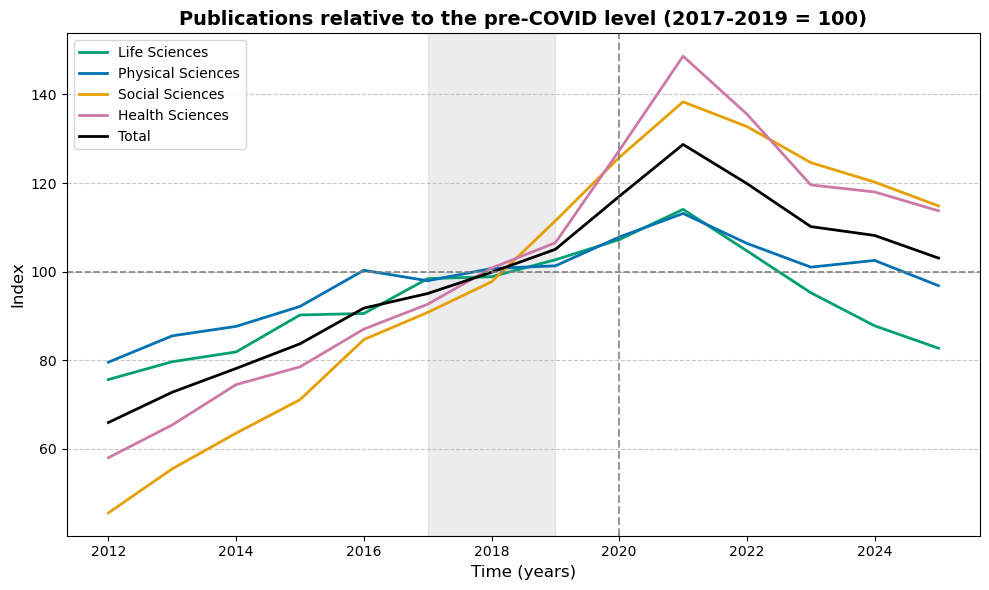

In [10]:
# COVID PEAK: level with respect to the pre-COVID base (mean 2017-2019 = 100)
base = taula_total.loc[2017:2019].mean()
taula_index = taula_total.loc[2012:2025] / base * 100

pic_any = taula_index.loc[2020:].idxmax()
pic_valor = taula_index.loc[2020:].max() - 100
valor_2025 = taula_index.loc[2025] - 100
print(pd.DataFrame({"pic_year": pic_any, "pic_%_over_base": pic_valor.round(1), "2025_%_over_base": valor_2025.round(1)}))

fig, ax = plt.subplots(figsize=(10, 6))
for col in taula_index.columns:
    ax.plot(taula_index.index, taula_index[col], color=colors_tot[col], linewidth=2, label=col)
ax.axhline(y=100, color="gray", linestyle="--", linewidth=1.2)
ax.axvspan(2017, 2019, color="gray", alpha=0.15)  # base period
ax.axvline(x=2020, color="gray", linestyle="--", linewidth=1.5, alpha=0.8)
ax.set_title("Publications relative to the pre-COVID level (2017-2019 = 100)", fontsize=14, fontweight="bold")
ax.set_xlabel("Time (years)", fontsize=12)
ax.set_ylabel("Index", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.7)
ax.legend(loc="upper left")
plt.tight_layout()

plt.savefig(f"{output_dir}/covid_index_by_domain.png", dpi=300, bbox_inches="tight")
plt.show()

### PLOT 6: year-over-year growth

% change of each domain with respect to the previous year (2000-2023; red shade = 2019-2022). It shows when the growth changes around COVID-19 and if all the domains react in the same way.

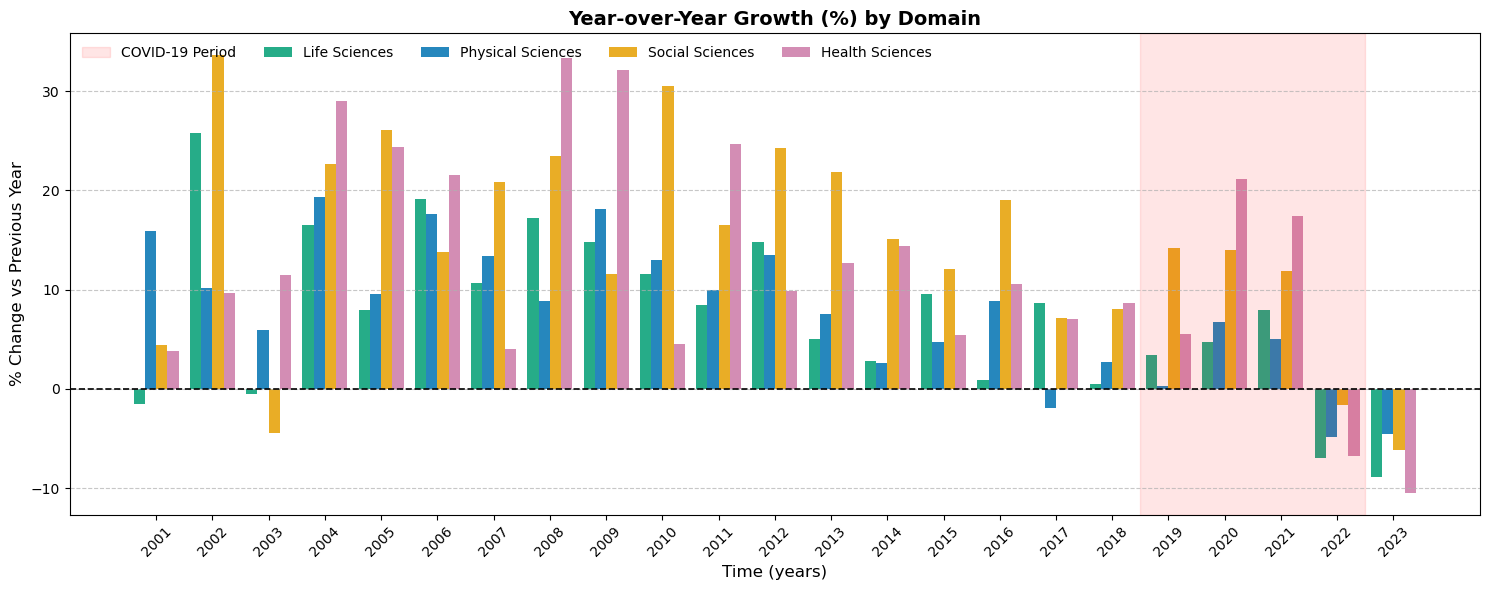

In [11]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
taula_dominis = taula_dominis[order]

# Filter the years: 2000-2023
taula_dominis = taula_dominis[(taula_dominis.index >= 2000) & (taula_dominis.index <= 2023)]

# Growth with respect to the previous year (%)
creixement = taula_dominis.pct_change() * 100
creixement = creixement.dropna() # the first year has no previous year

anys = creixement.index
colors_list = [colors[col] for col in creixement.columns]

# PLOT
fig, ax = plt.subplots(figsize=(15, 6))

# Width of each bar (4 bars per year)
width = 0.2
x = np.arange(len(anys))

# One bar per domain
for i, col in enumerate(creixement.columns):
    offset = (i - 1.5) * width # each bar is shifted to the right of the previous one
    ax.bar(x + offset, creixement[col], width, label=col, color=colors_list[i], alpha=0.85)

ax.set_title("Year-over-Year Growth (%) by Domain", fontsize=14, fontweight='bold')
ax.set_ylabel("% Change vs Previous Year", fontsize=12)
ax.set_xlabel("Time (years)", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(anys.astype(str), rotation=45)

# 0% line, to see positive and negative growth
ax.axhline(0, color='black', linewidth=1.2, linestyle='--')

# Shade the COVID-19 period (2019-2022)
idx_2019 = list(anys).index(2019)
idx_2022 = list(anys).index(2022)
ax.axvspan(idx_2019 - 0.5, idx_2022 + 0.5, color='red', alpha=0.1, label='COVID-19 Period')

ax.legend(loc='upper left', ncol=5, frameon=False)
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

#plt.savefig(f"{output_dir}/yearly_growth_by_domain.png", dpi=300, bbox_inches='tight')
plt.show()

### PLOT 7: publications by month (2019-2022)

Area chart by month and domain around the start of COVID-19 (March 2020) to see if the peak is visible month by month. `Unknown` (which are really few papers) are the papers without domain.

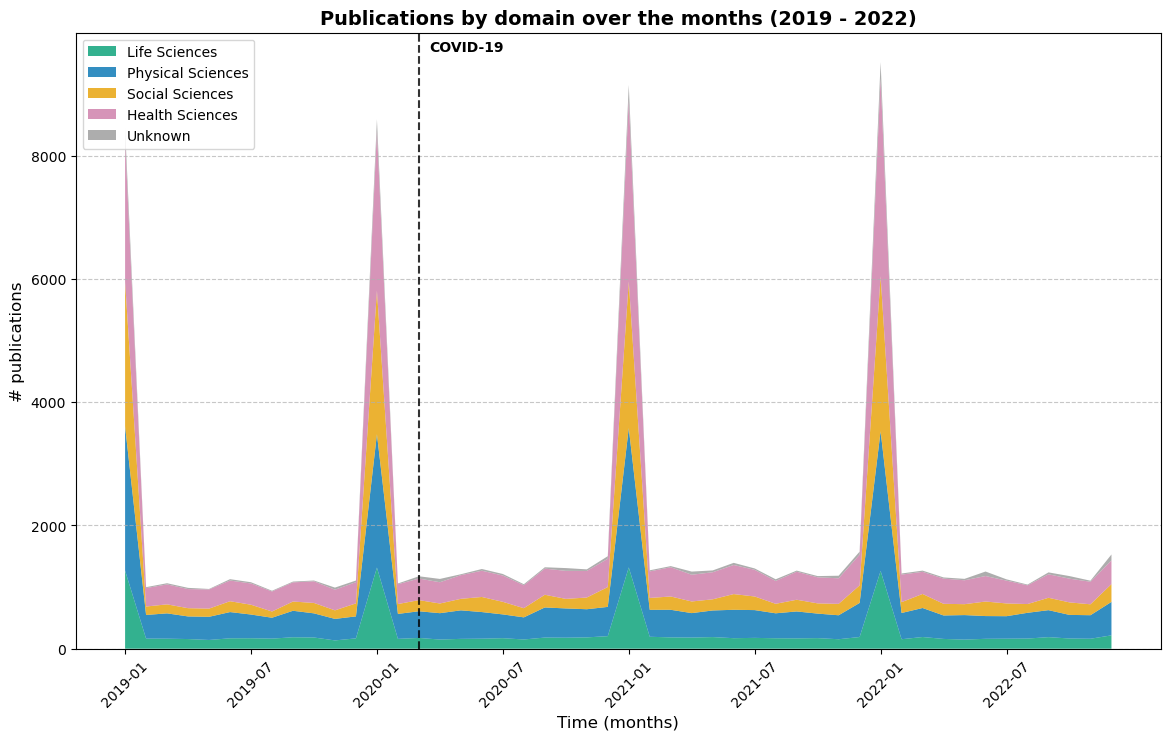

In [12]:
df = pd.read_parquet("../data/processed/all_papers_enriched_covid_months.parquet")

# New category: UNKNOWN (for topics we don't know)
df["domain_name"] = df["domain_name"].fillna("Unknown")
df["date_month"] = pd.to_datetime(df["year"].astype(str) + "-" + df["month"].astype(str).str.zfill(2))

colors_months = {**colors, 'Unknown': '#999999'}

# Table for the plot: rows = months, columns = domains, values = number of papers
taula_dominis = df.groupby(["date_month", "domain_name"]).size().unstack(fill_value=0)

# Order of the columns (Unknown at the end)
order_months = [col for col in order + ["Unknown"] if col in taula_dominis.columns]
taula_dominis = taula_dominis[order_months]

# Numeric index for the x axis (stackplot doesn't accept dates), and the month labels
x_vals = np.arange(len(taula_dominis.index))
etiquetes_mesos = [d.strftime('%Y-%m') for d in taula_dominis.index]

quantitats = [taula_dominis[col].values for col in taula_dominis.columns]
etiquetes = taula_dominis.columns.tolist()
colors_list = [colors_months[col] for col in etiquetes]

# PLOT
fig = plt.figure(figsize=(14, 8))
ax_main = fig.add_subplot(111)
ax_main.stackplot(x_vals, quantitats, labels=etiquetes, colors=colors_list, alpha=0.8)
ax_main.set_title("Publications by domain over the months (2019 - 2022)", fontsize=14, fontweight='bold')
ax_main.set_xlabel("Time (months)", fontsize=12)
ax_main.set_ylabel("# publications", fontsize=12)
ax_main.grid(axis='y', linestyle='--', alpha=0.7)
ax_main.legend(loc='upper left')

# Line to indicate when COVID-19 starts (March 2020)
try:
    index_covid = etiquetes_mesos.index('2020-03')
    ax_main.axvline(x=index_covid, color='black', linestyle='--', linewidth=1.5, alpha=0.8)
    ax_main.text(index_covid + 0.5, ax_main.get_ylim()[1]*0.97, 'COVID-19', color='black', fontsize=10, fontweight='bold')
except ValueError:
    pass # if the month is not in the data, no line

# Show a label every 6 months
ticks_posicions = np.arange(0, len(x_vals), 6)
ticks_etiquetes = [etiquetes_mesos[i] for i in ticks_posicions]
ax_main.set_xticks(ticks_posicions)
ax_main.set_xticklabels(ticks_etiquetes, rotation=45)

#plt.savefig(f"{output_dir}/area_chart_publications_by_domain_months.png", dpi=300, bbox_inches='tight')
plt.show()

Here we can see that the data we have doesn't really have useful information about the publication month. This is probably because most of the publications didn't have this information in the Gencat open data and, therefore, all the unsure dates were automatically classified at the beginning of each year (January 1st). So we can't study the effect of COVID-19 month by month.

## 5. Normalized evolution by domain

The domains have very different sizes, so to compare how each one evolves we normalize their numbers of publications.

### PLOT 8: deviation from the historical mean

$$Norm = \frac{H-\langle H\rangle}{\langle H\rangle} \times 100$$

- $H$: number of publications of the domain in a given year
- $\langle H\rangle$: mean of publications of the domain over the years (1985-2025)

With this normalization all the domains are on the same scale, so we can compare the shape of their growth (when it takes off and the COVID-19 peak) without the effect of their size.

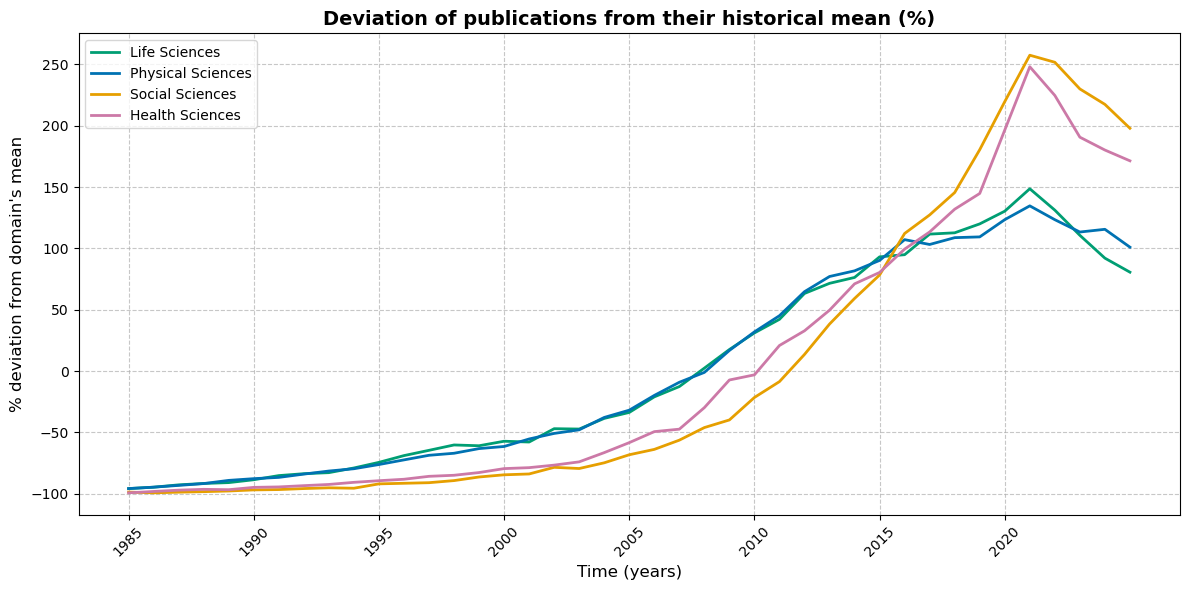

In [15]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
taula_dominis = taula_dominis[order]

# Filter the years: 1985-2025
taula_dominis = taula_dominis[(taula_dominis.index >= 1985) & (taula_dominis.index <= 2025)]

# NORMALIZATION: (H - <H>) / <H> (%)
mitjanes = taula_dominis.mean(axis=0)
taula_normalitzada = ((taula_dominis - mitjanes) / mitjanes) * 100

anys = taula_normalitzada.index

# PLOT
plt.figure(figsize=(12, 6))
for col in taula_normalitzada.columns:
    plt.plot(anys, taula_normalitzada[col], label=col, linewidth=2, color=colors[col])
plt.title("Deviation of publications from their historical mean (%)", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("% deviation from domain's mean", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
ticks_anys = np.arange(1985, 2025, 5)
plt.xticks(ticks_anys, rotation=45)
plt.legend(loc='upper left')
plt.tight_layout()

plt.savefig(f"{output_dir}/deviation_publications_from_history.png", dpi=300, bbox_inches='tight')
plt.show()

### PLOT 9: contribution to the annual deviation

$$Norm = \frac{H-\langle H\rangle}{T} \times 100$$

- $H$: number of publications of the domain in a given year
- $\langle H\rangle$: mean of publications of the domain over the years (2000-2025)
- $T$: total publications of that year (all the domains)

Here the deviation of each domain is divided by the total of the year, so we see how much each domain adds to (or takes from) the total, in % of the publications of that year.

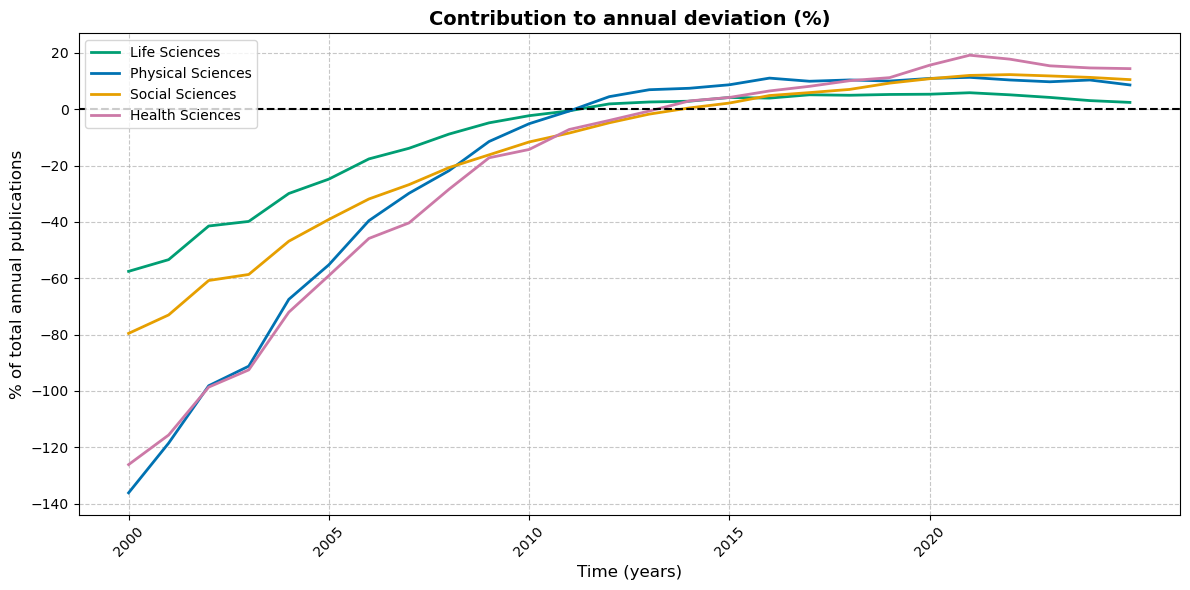

In [16]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
taula_dominis = taula_dominis[order]

# Filter the years: 2000-2025
taula_dominis = taula_dominis[(taula_dominis.index >= 2000) & (taula_dominis.index <= 2025)]

# Deviation of each domain from its mean, divided by the total of that year
mitjanes = taula_dominis.mean(axis=0)
desviacio = taula_dominis - mitjanes
total_anual = taula_dominis.sum(axis=1)
taula_normalitzada = desviacio.div(total_anual, axis=0) * 100

anys = taula_normalitzada.index

# PLOT
plt.figure(figsize=(12, 6))
for col in taula_normalitzada.columns:
    plt.plot(anys, taula_normalitzada[col], label=col, linewidth=2, color=colors[col])

plt.title("Contribution to annual deviation (%)", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("% of total annual publications", fontsize=12)
plt.axhline(0, color='black', linewidth=1.5, linestyle='--')
plt.grid(True, linestyle='--', alpha=0.7)
ticks_anys = np.arange(2000, 2025, 5)
plt.xticks(ticks_anys, rotation=45)
plt.legend(loc='upper left')
plt.tight_layout()

#plt.savefig(f"{output_dir}/deviation_relative_to_total.png", dpi=300, bbox_inches='tight')
plt.show()

## 6. Contribution of each domain to the total

How much each domain contributes to the total of publications, and how it changes over time. We show it in four ways: lines, bars for selected years (vertical and horizontal) and a continuous area.

### PLOT 10: share of the total publications by domain

% of the publications of each year that belongs to each domain. The dotted line is the equal share --> 25%, if the four domains published the same.

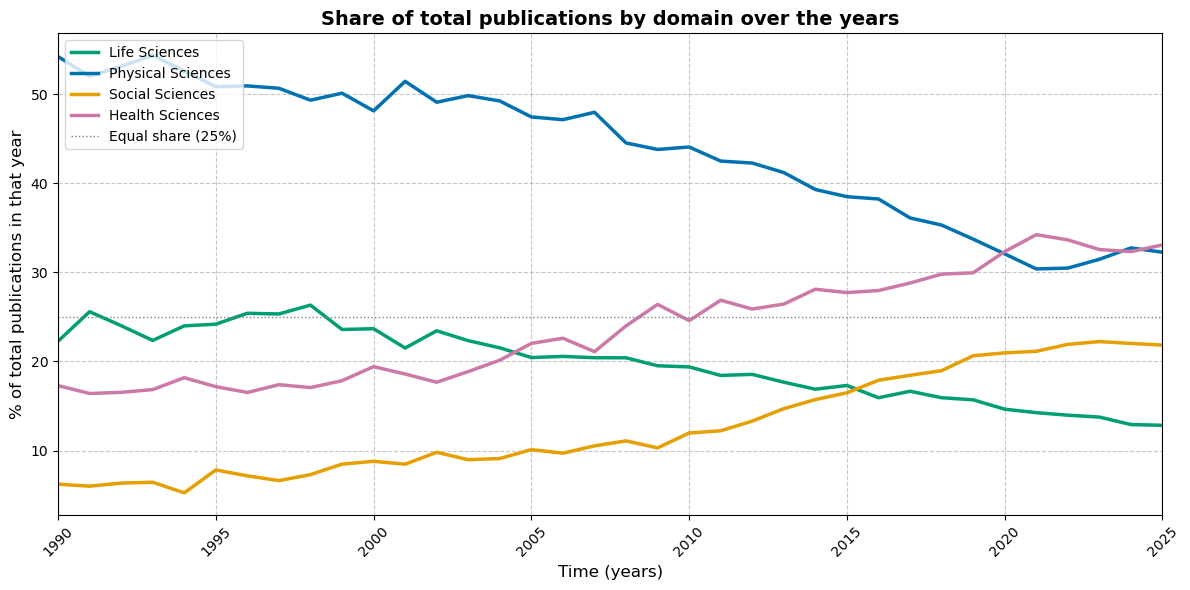

In [17]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
taula_dominis = taula_dominis[order]

# Divide each domain by the total publications of that year (%)
taula_percentatges = taula_dominis.div(taula_dominis.sum(axis=1), axis=0) * 100

# Filter the years: 1990-2025
taula_percentatges = taula_percentatges[(taula_percentatges.index >= 1990) & (taula_percentatges.index <= 2025)]

anys = taula_percentatges.index

# PLOT
plt.figure(figsize=(12, 6))
for col in taula_percentatges.columns:
    plt.plot(anys, taula_percentatges[col], label=col, linewidth=2.5, color=colors[col])

plt.title("Share of total publications by domain over the years", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("% of total publications in that year", fontsize=12)
plt.axhline(25, color='gray', linewidth=1, linestyle=':', label='Equal share (25%)') # equal share of the 4 domains
plt.grid(True, linestyle='--', alpha=0.7)
ticks_anys = np.arange(1990, 2026, 5)
plt.xticks(ticks_anys, rotation=45)
plt.xlim(1990, 2025)
plt.legend(loc='upper left')
plt.tight_layout()

#plt.savefig(f"{output_dir}/share_by_domain_lines.png", dpi=300, bbox_inches='tight')
plt.show()

### PLOT 11: shares in selected years (vertical bars)

Proportion of each domain in some selected years: before the growth (1980, 2000), the COVID-19 years (2019-2022) and the end of the series (2025).

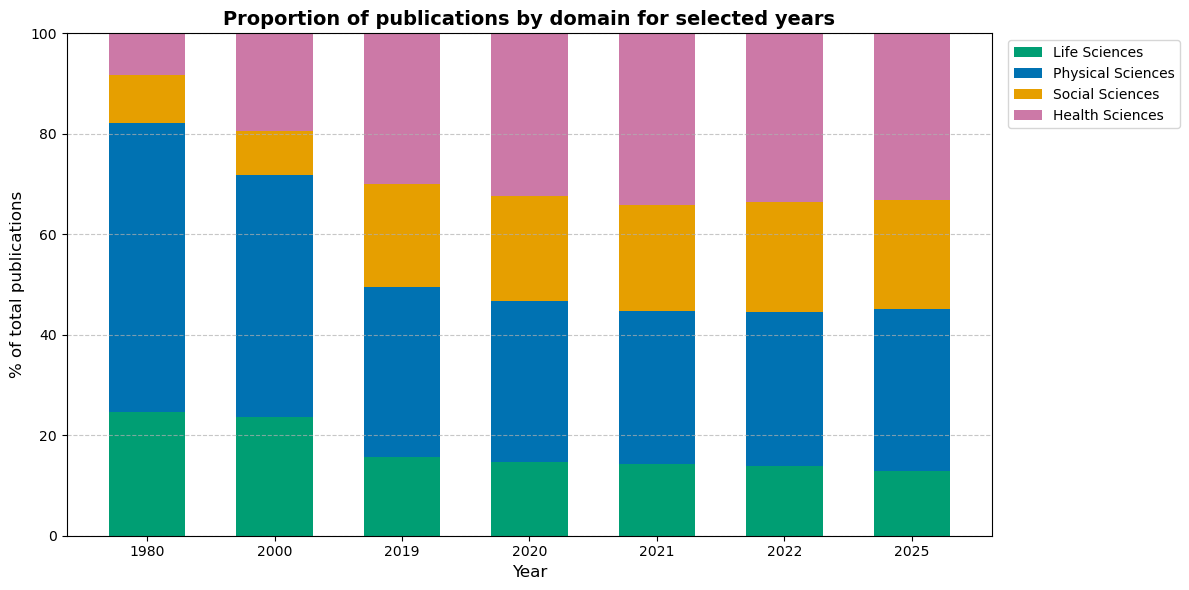

In [18]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
taula_dominis = taula_dominis[order]

# YEARS WE WANT TO SHOW
anys_a_mostrar = [1980, 2000, 2019, 2020, 2021, 2022, 2025]

taula_seleccio = taula_dominis.loc[taula_dominis.index.isin(anys_a_mostrar)]
taula_percent = taula_seleccio.div(taula_seleccio.sum(axis=1), axis=0) * 100

# PLOT
fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(taula_percent))
for col in taula_percent.columns:
    ax.bar(taula_percent.index.astype(str), taula_percent[col],
           bottom=bottom, label=col, color=colors[col], width=0.6)
    bottom += taula_percent[col].values
ax.set_title("Proportion of publications by domain for selected years", fontsize=14, fontweight='bold')
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("% of total publications", fontsize=12)
ax.set_ylim(0, 100)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1)) # legend outside
plt.tight_layout()

#plt.savefig(f"{output_dir}/proportion_by_domain_selected_years.png", dpi=300, bbox_inches='tight')
plt.show()

### PLOT 12: shares in selected years (horizontal bars)

Compact version for one year per decade (1990, 2000, 2010, 2020), with the % written inside the bars. We label only the segments that are big enough to be readable.

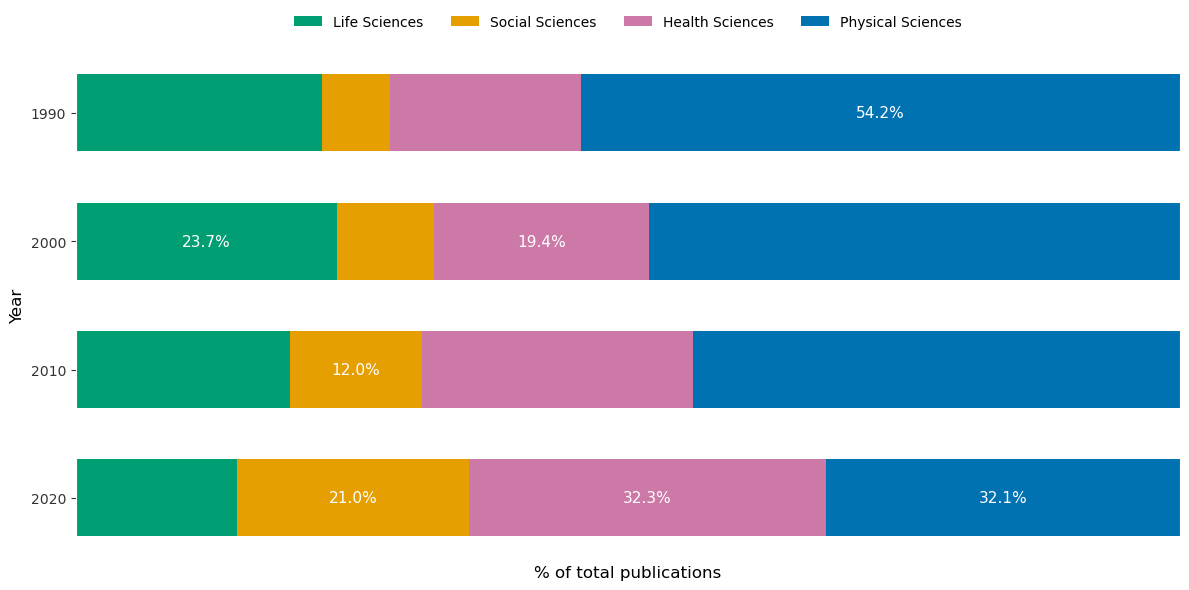

In [19]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
order_bars = ["Life Sciences", "Social Sciences", "Health Sciences", "Physical Sciences"]
taula_dominis = taula_dominis[order_bars]

anys_a_mostrar = [1990, 2000, 2010, 2020]
taula_seleccio = taula_dominis.loc[taula_dominis.index.isin(anys_a_mostrar)]
taula_percent = taula_seleccio.div(taula_seleccio.sum(axis=1), axis=0) * 100

colors_list = [colors[col] for col in taula_percent.columns]

# PLOT: horizontal stacked bars (years in the y axis)
fig, ax = plt.subplots(figsize=(12, 6))

anys_str = taula_percent.index.astype(str)
left = np.zeros(len(taula_percent)) # start of each bar (like 'bottom' for vertical bars)

for i, col in enumerate(taula_percent.columns):
    ax.barh(anys_str, taula_percent[col],
            left=left, label=col, color=colors_list[i], height=0.6)
    left += taula_percent[col].values

# Style
ax.set_ylabel("Year", fontsize=12)
ax.set_xlabel("% of total publications", fontsize=12)
ax.set_xlim(0, 100)
ax.grid(axis='x', linestyle='--', alpha=0.7)
ax.invert_yaxis()
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=4, title="", frameon=False)
for spine in ax.spines.values():
    spine.set_color("#FFFFFF") # hide the frame
ax.tick_params(axis='both', colors='#333333')
ax.set_xticks([])

# Segments (year, domain) that get the % label
etiquetes_demanades = {
    (1990, "Physical Sciences"): "Physical",
    (2000, "Life Sciences"): "Life",
    (2000, "Health Sciences"): "Health",
    (2010, "Social Sciences"): "Social",
    (2020, "Social Sciences"): "Social",
    (2020, "Health Sciences"): "Health",
    (2020, "Physical Sciences"): "Physical"
}

for (any_sel, domini_sel), nom_curt in etiquetes_demanades.items():
    if any_sel in taula_percent.index:
        # Start of the segment: sum of the segments on its left
        index_col = taula_percent.columns.get_loc(domini_sel)
        if index_col == 0:
            x_pos = 0
        else:
            x_pos = taula_percent.iloc[list(taula_percent.index).index(any_sel), :index_col].sum()

        # Text in the middle of the segment
        amplada = taula_percent.loc[any_sel, domini_sel]
        x_mig = x_pos + (amplada / 2)
        valor_text = taula_percent.loc[any_sel, domini_sel]
        ax.text(x_mig, str(any_sel), f"{valor_text:.1f}%",
                ha='center', va='center', color='white', fontsize=11)

plt.tight_layout()

plt.savefig(f"{output_dir}/horizontal_bars_proportion_by_year.png", dpi=300, bbox_inches="tight")
plt.show()

### PLOT 13: continuous share (area)

Same information as the bars, but for every year (1990-2025) instead of selected ones, so there is no need to choose years. It uses `taula_dominis` and `order_bars` (domain order) of the previous plot.

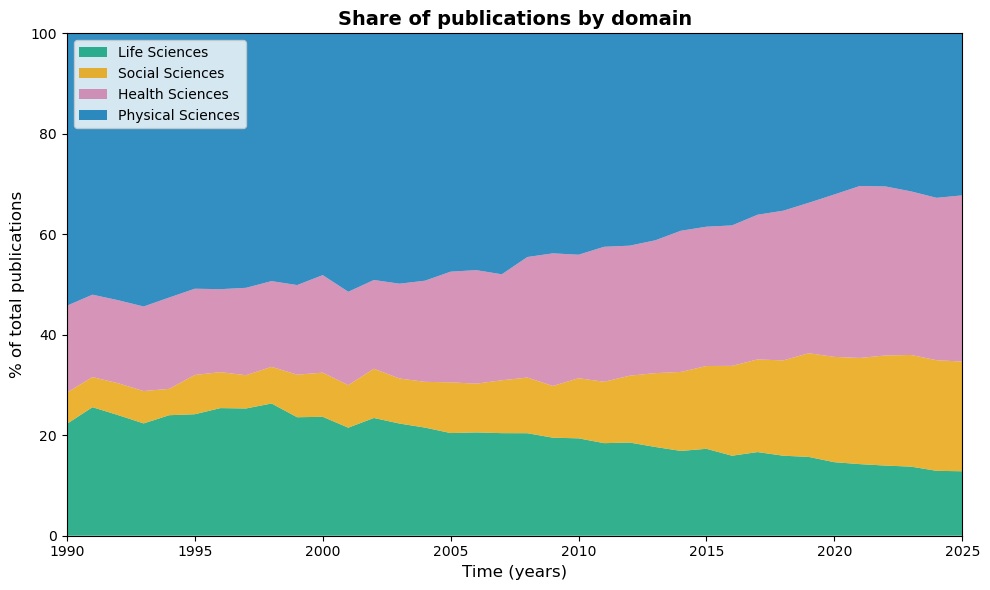

In [20]:
# Continuous domain contribution to the total
taula_pct = taula_dominis.div(taula_dominis.sum(axis=1), axis=0) * 100
taula_pct = taula_pct.loc[1990:2025, order_bars] # same domain order as the horizontal bars

fig, ax = plt.subplots(figsize=(10, 6))
ax.stackplot(taula_pct.index, [taula_pct[col].values for col in taula_pct.columns],
             labels=taula_pct.columns.tolist(), colors=[colors[col] for col in taula_pct.columns], alpha=0.8)
ax.set_xlim(1990, 2025)
ax.set_ylim(0, 100)
ax.set_title("Share of publications by domain", fontsize=14, fontweight="bold")
ax.set_xlabel("Time (years)", fontsize=12)
ax.set_ylabel("% of total publications", fontsize=12)
ax.legend(loc="upper left")
plt.tight_layout()

plt.savefig(f"{output_dir}/share_by_domain_area.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Domains and topics

### PLOT 14: publications by domain in different panels

Each domain in its own panel (each one with its own scale), to see the shape of the evolution of the small domains.

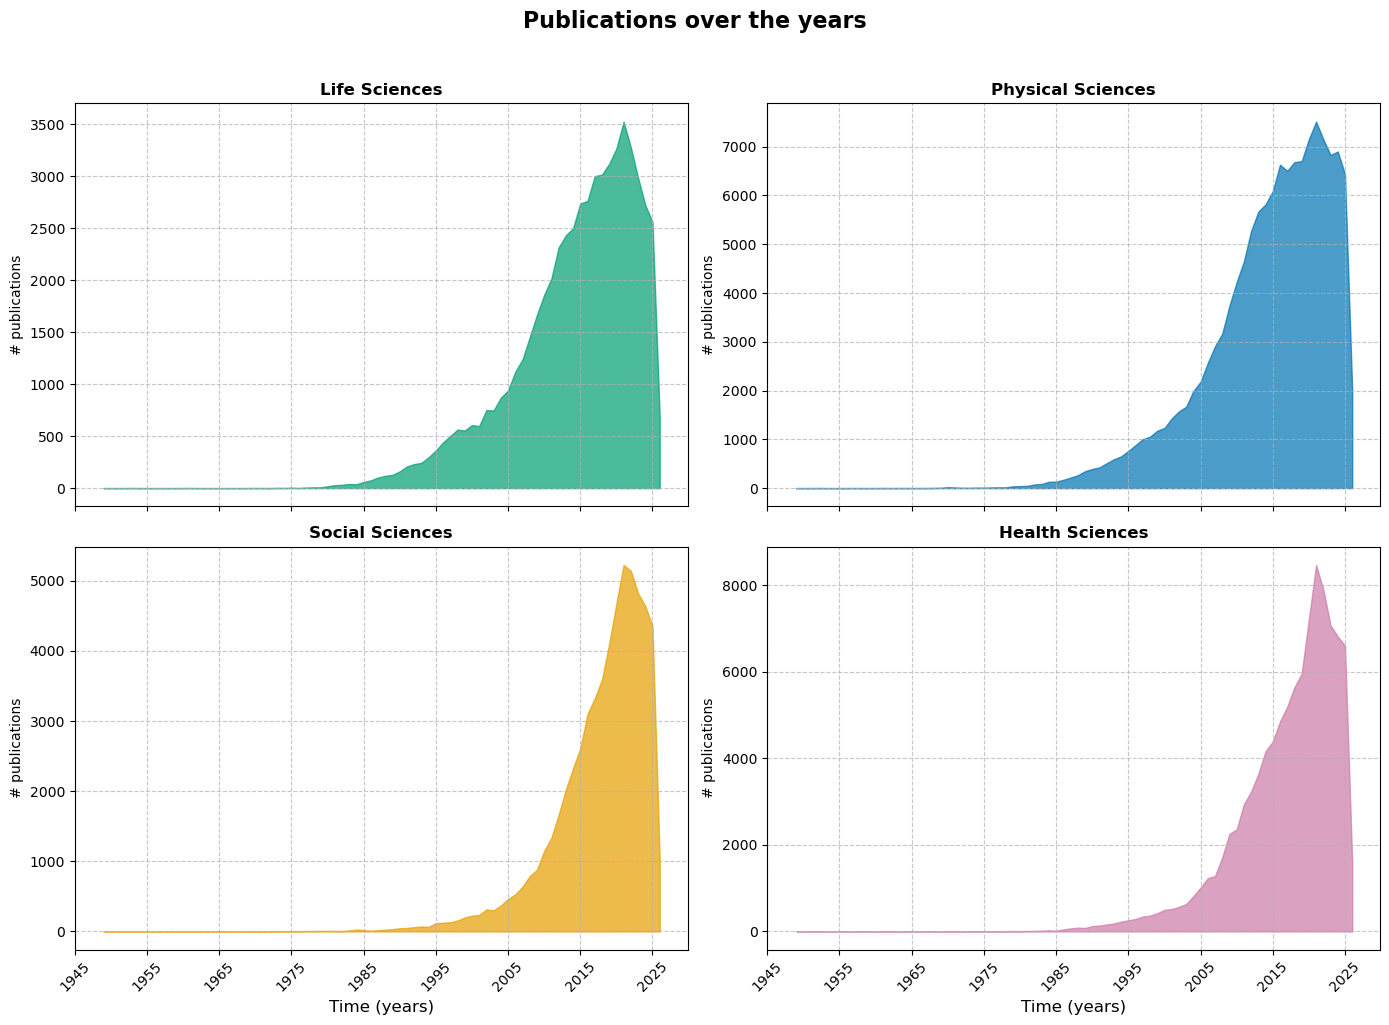

In [21]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
taula_dominis = taula_dominis[order]

anys = taula_dominis.index

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10), sharex=True)
axes = axes.flatten()

for i, domini in enumerate(order):
    ax = axes[i]
    ax.fill_between(anys, taula_dominis[domini], color=colors[domini], alpha=0.7, label=domini)
    ax.set_title(domini, fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.set_ylabel("# publications")
    ticks_anys = np.arange(1945, max(anys) + 1, 10)
    ax.set_xticks(ticks_anys)

fig.suptitle("Publications over the years", fontsize=16, fontweight='bold', y=1.02)
axes[2].set_xlabel("Time (years)", fontsize=12)
axes[3].set_xlabel("Time (years)", fontsize=12)
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()

#plt.savefig(f"{output_dir}/publications_by_domain_panels.png", dpi=300, bbox_inches='tight')
plt.show()

### PLOT 16: topics within each domain

Stacked publications per year by their primary topic (OpenAlex field) inside each domain. It shows which topics drive the trend of each domain. Topics have no fixed color (default color cycle).

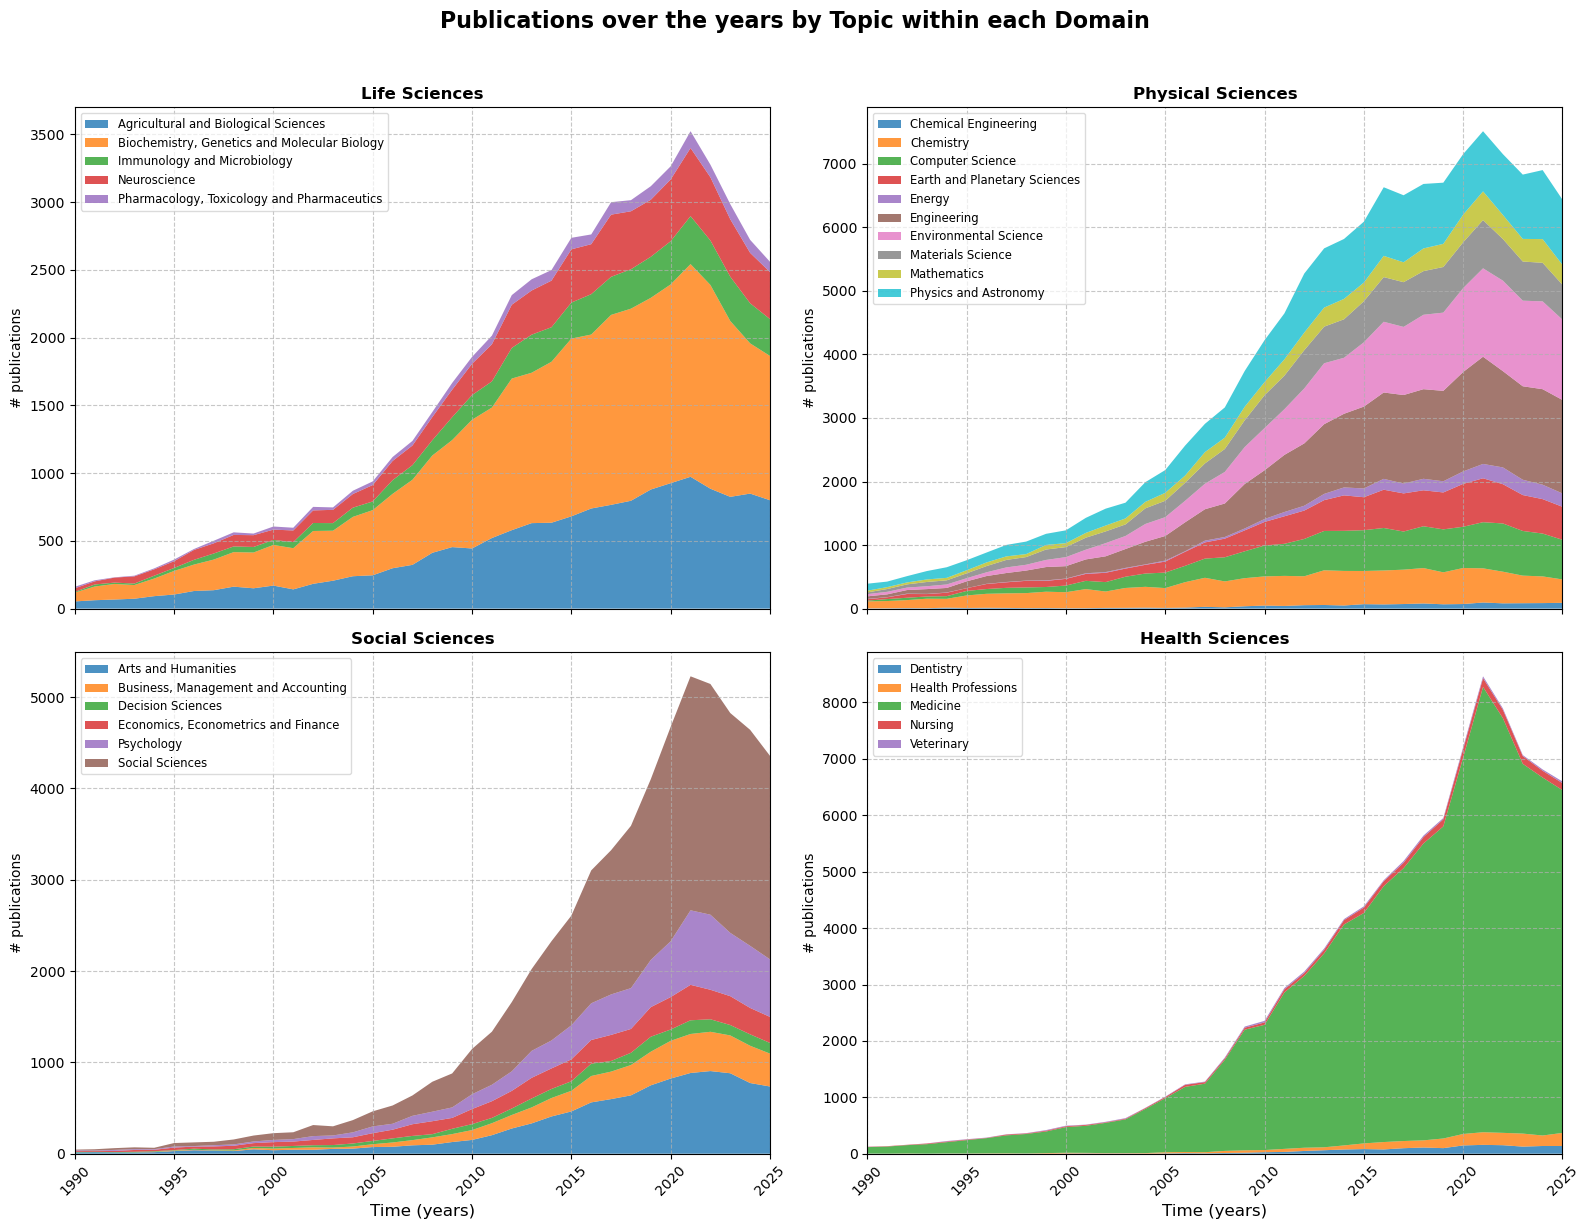

In [22]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name", "field_name"]) # we need both
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12), sharex=True)
axes = axes.flatten()

for i, domini in enumerate(order):
    ax = axes[i]

    df_dom = df_plots[df_plots["domain_name"] == domini]
    taula_topics = df_dom.groupby(["year", "field_name"]).size().unstack(fill_value=0)

    # If we only want the 5 biggest topics
    #top_topics = taula_topics.sum().nlargest(5).index
    #taula_topics = taula_topics[top_topics]

    taula_topics = taula_topics[(taula_topics.index >= 1990) & (taula_topics.index <= 2025)]

    anys = taula_topics.index
    quantitats = [taula_topics[col].values for col in taula_topics.columns]
    etiquetes = taula_topics.columns.tolist()
    ax.stackplot(anys, quantitats, labels=etiquetes, alpha=0.8)
    ax.set_title(f"{domini}", fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.set_ylabel("# publications")
    ax.set_xlim(1990, 2025)
    ax.margins(x=0)
    ticks_anys = np.arange(1990, 2026, 5)
    ax.set_xticks(ticks_anys)
    ax.legend(loc='upper left', fontsize='small', framealpha=0.7)

fig.suptitle("Publications over the years by Topic within each Domain", fontsize=16, fontweight='bold', y=1.02)
axes[2].set_xlabel("Time (years)", fontsize=12)
axes[3].set_xlabel("Time (years)", fontsize=12)
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()

#plt.savefig(f"{output_dir}/publications_by_topic_within_domain.png", dpi=300, bbox_inches='tight')
plt.show()